In [100]:
%pip install datasets pandas pyarrow matplotlib seaborn scikit-learn

You should consider upgrading via the '/Users/andreacaceres/cu boulder/2026 Semester/Projects in DS/andreaycaceres.github.io/.venv/bin/python -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [101]:
import pandas as pd
import matplotlib as plt
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics import f1_score, precision_score, recall_score

In [102]:
df = pd.read_parquet("hf://datasets/Z02Z/steam-games-dataset/data/train-00000-of-00001.parquet")

In [103]:
#EDA
print(df.shape)
print(df.head())
print(df.info())
# investigate missing values
print(df.isnull().sum())
print(df.describe())

(122876, 41)
     appID                                   name  release_date  \
0  2539430             Black Dragon Mage Playtest   Aug 1, 2023   
1   496350  Supipara - Chapter 1 Spring Has Come!  Jul 29, 2016   
2  1034400      Mystery Solitaire The Black Raven   May 6, 2019   
3  3292190            버튜버 파라노이아 - Vtuber Paranoia  Oct 31, 2024   
4  3631080                          Maze Quest VR  Apr 24, 2025   

  estimated_owners  peak_ccu  required_age  price  dlc_count  \
0            0 - 0         0             0   0.00          0   
1        0 - 20000         0             0   5.24          0   
2        0 - 20000         0             0   4.99          0   
3        0 - 20000         1             0   8.99          1   
4        0 - 20000         0             0   4.99          0   

                                detailed_description  \
0                                                      
1  Springtime, April: when the cherry trees come ...   
2  Immerse yourself in the most

In [ ]:
print(df.columns.tolist())
features = ['estimated_owners', 'price', 'genres', 'release_date', 'windows', 'mac', 'linux', 'required_age']
games_df =df[features].copy()
games_df.head()

['appID', 'name', 'release_date', 'estimated_owners', 'peak_ccu', 'required_age', 'price', 'dlc_count', 'detailed_description', 'short_description', 'supported_languages', 'full_audio_languages', 'reviews', 'header_image', 'website', 'support_url', 'support_email', 'windows', 'mac', 'linux', 'metacritic_score', 'metacritic_url', 'user_score', 'positive', 'negative', 'score_rank', 'achievements', 'recommendations', 'notes', 'average_playtime_forever', 'average_playtime_2weeks', 'median_playtime_forever', 'median_playtime_2weeks', 'developers', 'publishers', 'categories', 'genres', 'tags', 'screenshots', 'movies', 'packages']


,estimated_owners,price,genres,release_date,windows,mac,linux,required_age
0,0 - 0,0.00,[],"Aug 1, 2023",True,False,False,0
1,0 - 20000,5.24,[Adventure],"Jul 29, 2016",True,False,False,0
2,0 - 20000,4.99,[Casual],"May 6, 2019",True,True,False,0
3,0 - 20000,8.99,"[Casual, Indie, Simulation]","Oct 31, 2024",True,False,False,0
4,0 - 20000,4.99,"[Action, Early Access]","Apr 24, 2025",True,False,False,0


At this point I am going to choose features that relate to the games on Steam prior to any player activity to prevent data leakage. 

In [105]:
games_df["estimated_owners"].value_counts().head(20)

estimated_owners
0 - 20000                75425
0 - 0                    21885
20000 - 50000            11396
50000 - 100000            5355
100000 - 200000           3454
200000 - 500000           2853
500000 - 1000000          1154
1000000 - 2000000          729
2000000 - 5000000          405
5000000 - 10000000         125
10000000 - 20000000         51
20000000 - 50000000         31
50000000 - 100000000         9
100000000 - 200000000        4
Name: count, dtype: int64

In [106]:
games_df["owners_min"] = games_df["estimated_owners"].str.split(" - ").str[0].astype(int)
games_df["popular"] = (games_df["owners_min"] >= 100000).astype(int)
games_df["popular"].value_counts()

popular
0    114061
1      8815
Name: count, dtype: int64

In [107]:
games_df[features].dtypes

estimated_owners     object
price               float64
genres               object
release_date         object
windows                bool
mac                    bool
linux                  bool
required_age          int64
dtype: object

In [108]:
#since we cant use dates as a feature, we will have to extract the year and month
games_df['release_year']=pd.to_datetime(games_df['release_date'], format='%b %d, %Y', errors='coerce').dt.year
games_df['release_month']=pd.to_datetime(games_df['release_date'], format='%b %d, %Y', errors='coerce').dt.month
print(games_df[['release_year','release_month']].head(10))
games_df[['release_year','release_month']].isnull().sum() #check missing vals

   release_year  release_month
0          2023              8
1          2016              7
2          2019              5
3          2024             10
4          2025              4
5          2023              4
6          2025              4
7          2018              2
8          2021              5
9          2021             12


release_year     0
release_month    0
dtype: int64

In [109]:
games_df['genres'].head(10)

0                                   []
1                          [Adventure]
2                             [Casual]
3          [Casual, Indie, Simulation]
4               [Action, Early Access]
5                  [Action, Adventure]
6               [Simulation, Strategy]
7                      [Action, Indie]
8                      [Casual, Indie]
9    [Action, Casual, Indie, Strategy]
Name: genres, dtype: object

Since some games fall into different genres, a one hot encoder would not be the most efficient. Using multi-hot encoding or multi-label binarization would be the best approach for this since some games do not just have one type of genre.

In [110]:
mlb = MultiLabelBinarizer()
encoded_genres=mlb.fit_transform(games_df['genres'])
genres_df=pd.DataFrame(encoded_genres, columns=mlb.classes_, index=games_df.index)
genres_df.head(10)
print(mlb.classes_)
genres_df.sum().sort_values(ascending=False)

['360 Video' 'Accounting' 'Action' 'Adventure' 'Animation & Modeling'
 'Audio Production' 'Casual' 'Design & Illustration' 'Documentary'
 'Early Access' 'Education' 'Episodic' 'Free To Play' 'Game Development'
 'Gore' 'Indie' 'Massively Multiplayer' 'Movie' 'Nudity' 'Photo Editing'
 'RPG' 'Racing' 'Sexual Content' 'Short' 'Simulation' 'Software Training'
 'Sports' 'Strategy' 'Tutorial' 'Utilities' 'Video Production' 'Violent'
 'Web Publishing']


Indie                    80831
Casual                   50332
Action                   46322
Adventure                45237
Simulation               24189
Strategy                 22456
RPG                      21028
Free To Play             12208
Early Access             11130
Sports                    4893
Racing                    4084
Massively Multiplayer     2536
Utilities                 1080
Design & Illustration      583
Animation & Modeling       479
Education                  461
Violent                    414
Video Production           339
Game Development           322
Gore                       257
Audio Production           225
Software Training          219
Photo Editing              182
Web Publishing             112
Nudity                      94
Sexual Content              88
Accounting                  30
Movie                        2
Short                        1
Tutorial                     1
Episodic                     1
Documentary                  1
360 Vide

To get the best coefficient results, for this project I will be removing any genres that have less than 100 games.

In [87]:
genre_counts=genres_df.sum()
keep = genre_counts[genre_counts >= 100].index
genres_df = genres_df[keep]
print(genres_df.sum().sort_values(ascending=False))

games_df = pd.concat([games_df.drop(columns=['genres', 'estimated_owners','owners_min','release_date']), genres_df],axis=1)
print(games_df.head(10))

Indie                    80831
Casual                   50332
Action                   46322
Adventure                45237
Simulation               24189
Strategy                 22456
RPG                      21028
Free To Play             12208
Early Access             11130
Sports                    4893
Racing                    4084
Massively Multiplayer     2536
Utilities                 1080
Design & Illustration      583
Animation & Modeling       479
Education                  461
Violent                    414
Video Production           339
Game Development           322
Gore                       257
Audio Production           225
Software Training          219
Photo Editing              182
Web Publishing             112
dtype: int64
   price  windows    mac  linux  required_age  popular  release_year  \
0   0.00     True  False  False             0        0          2023   
1   5.24     True  False  False             0        0          2016   
2   4.99     True   True  F

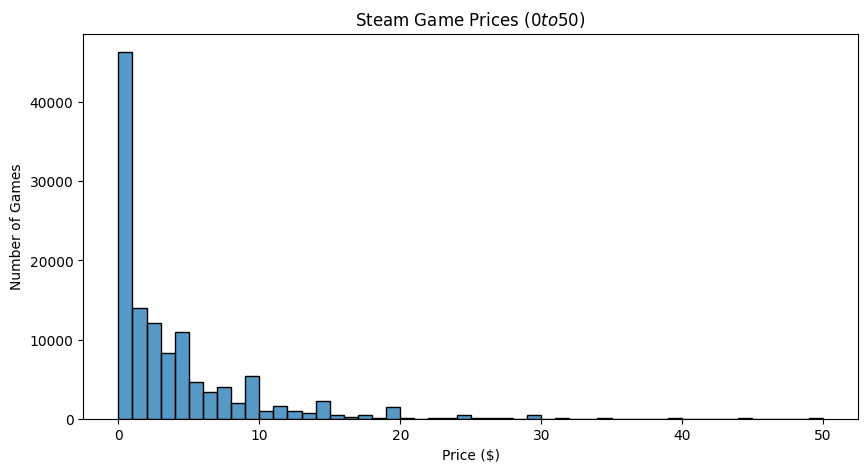

In [88]:
plt.figure(figsize=(10, 5))
sns.histplot(
games_df.loc[games_df["price"] <= 50, "price"],
bins=50)
plt.title("Steam Game Prices ($0 to $50)")
plt.xlabel("Price ($)")
plt.ylabel("Number of Games")
plt.show()

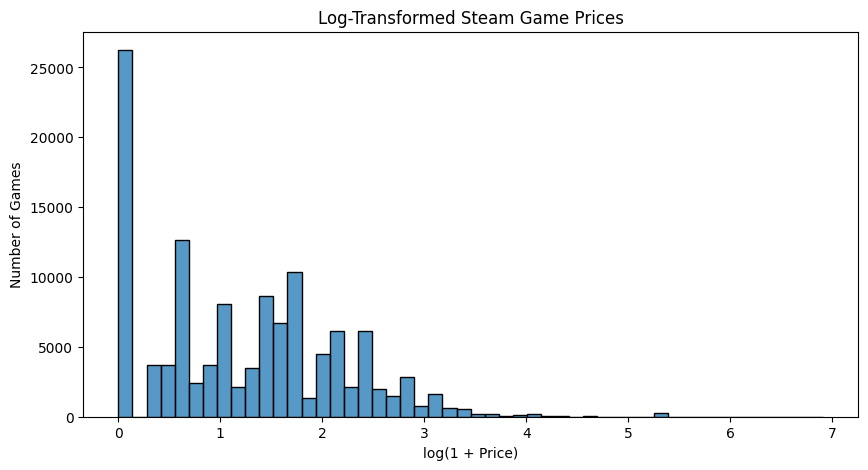

In [89]:
plt.figure(figsize=(10, 5))

sns.histplot(np.log1p(games_df["price"]), bins=50)

plt.title("Log-Transformed Steam Game Prices")
plt.xlabel("log(1 + Price)")
plt.ylabel("Number of Games")

plt.show()

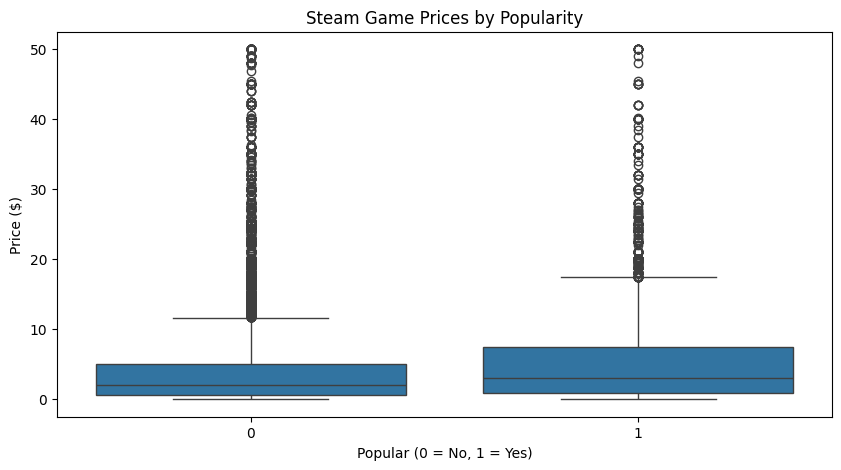

In [90]:
plt.figure(figsize=(10, 5))
sns.boxplot(
data=games_df[games_df["price"] <= 50],
x="popular",
y="price"
)

plt.title("Steam Game Prices by Popularity")
plt.xlabel("Popular (0 = No, 1 = Yes)")
plt.ylabel("Price ($)")

plt.show()

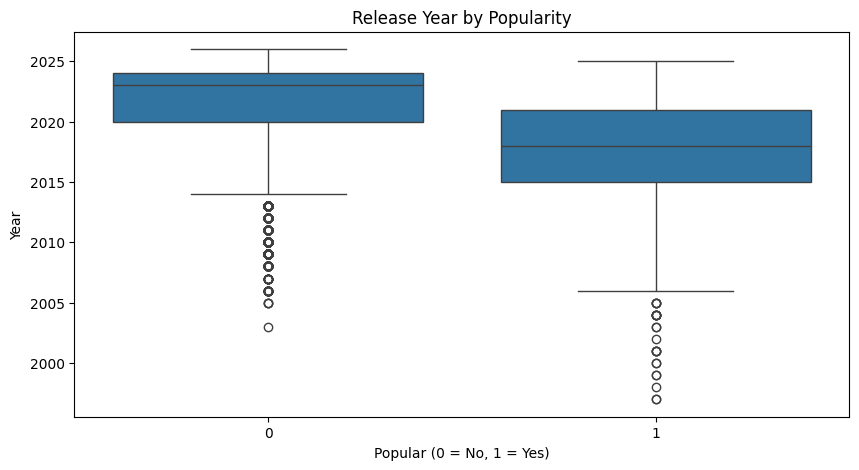

In [91]:
plt.figure(figsize=(10, 5))
sns.boxplot(
data=games_df[games_df["price"] <= 50],
x="popular",
y="release_year"
)
plt.title("Release Year by Popularity")
plt.xlabel("Popular (0 = No, 1 = Yes)")
plt.ylabel("Year")

plt.show()

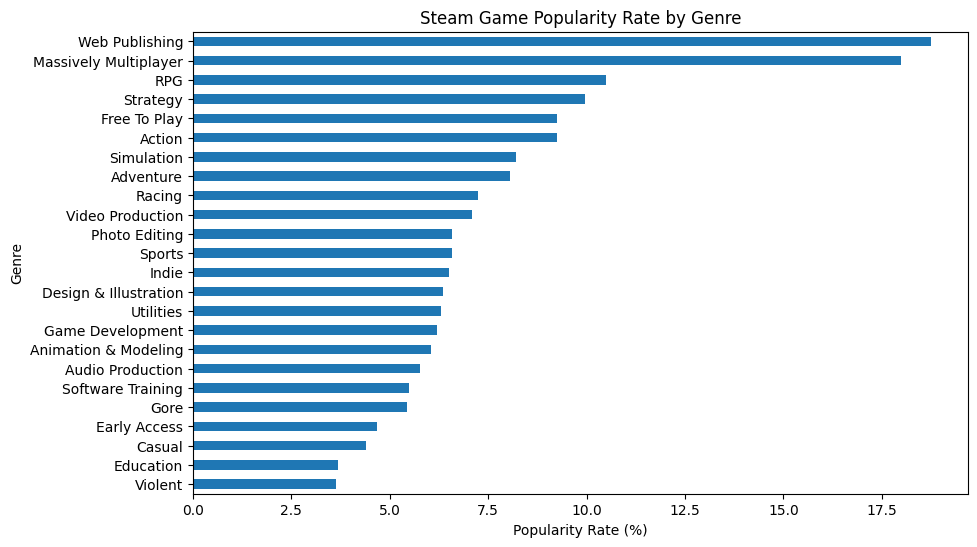

In [92]:
genre_rates = {
    genre: games_df.loc[games_df[genre] == 1, 'popular'].mean() * 100
    for genre in genres_df.columns
}

genre_rates = pd.Series(genre_rates).sort_values()

genre_rates.plot(kind='barh', figsize=(10, 6))
plt.xlabel('Popularity Rate (%)')
plt.ylabel('Genre')
plt.title('Steam Game Popularity Rate by Genre')
plt.show()

In [93]:
#splitting data into train and test sets
X = games_df.drop(columns=['popular'])
y = games_df['popular']
print(X.shape, y.shape)


#split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

(122876, 31) (122876,)


In [94]:
print("Training:", X_train.shape)
print("Testing:", X_test.shape)
print("Training popularity:", y_train.mean())
print("Testing popularity:", y_test.mean())

Training: (98300, 31)
Testing: (24576, 31)
Training popularity: 0.07173957273652086
Testing popularity: 0.07173665364583333


In [ ]:
#standardizing the nummerical features
numerical_cols = ['price', 'release_year', 'release_month', 'required_age']
scaler=StandardScaler()
X_trained_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_trained_scaled[numerical_cols] = scaler.fit_transform(X_train[numerical_cols])
X_test_scaled[numerical_cols]= scaler.transform(X_test[numerical_cols])
print(X_trained_scaled.mean().round(2))
print(X_test_scaled.std().round(2))

price                   -0.00
windows                  1.00
mac                      0.17
linux                    0.13
required_age            -0.00
release_year            -0.00
release_month            0.00
Action                   0.38
Adventure                0.37
Animation & Modeling     0.00
Audio Production         0.00
Casual                   0.41
Design & Illustration    0.00
Early Access             0.09
Education                0.00
Free To Play             0.10
Game Development         0.00
Gore                     0.00
Indie                    0.66
Massively Multiplayer    0.02
Photo Editing            0.00
RPG                      0.17
Racing                   0.03
Simulation               0.20
Software Training        0.00
Sports                   0.04
Strategy                 0.18
Utilities                0.01
Video Production         0.00
Violent                  0.00
Web Publishing           0.00
dtype: float64
price                    0.91
windows                  

In [96]:
model = LogisticRegression(max_iter=1000)
model.fit(X_trained_scaled, y_train)
y_pred =model.predict(X_test_scaled)

/Users/andreacaceres/cu boulder/2026 Semester/Projects in DS/andreaycaceres.github.io/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/andreacaceres/cu boulder/2026 Semester/Projects in DS/andreaycaceres.github.io/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/andreacaceres/cu boulder/2026 Semester/Projects in DS/andreaycaceres.github.io/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/andreacaceres/cu boulder/2026 Semester/Projects in DS/andreaycaceres.github.io/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features

In [97]:
coefficients = pd.DataFrame({
"Feature": X_trained_scaled.columns,
"Coefficient": model.coef_[0]
})

print(coefficients.sort_values("Coefficient", ascending=False))

                  Feature  Coefficient
15           Free To Play     0.642908
19  Massively Multiplayer     0.596427
2                     mac     0.577689
30         Web Publishing     0.490500
21                    RPG     0.448846
23             Simulation     0.448606
26               Strategy     0.424825
7                  Action     0.409631
27              Utilities     0.262017
4            required_age     0.210794
8               Adventure     0.209153
16       Game Development     0.123201
28       Video Production     0.108352
3                   linux     0.081835
22                 Racing     0.072886
0                   price     0.046020
20          Photo Editing    -0.014399
6           release_month    -0.075403
9    Animation & Modeling    -0.119370
10       Audio Production    -0.127826
25                 Sports    -0.190954
24      Software Training    -0.204788
12  Design & Illustration    -0.272777
18                  Indie    -0.300881
13           Early Access

In [98]:
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]
print("f1 score:", f1_score(y_test, y_pred))
print("precision:", precision_score(y_test, y_pred))
print("recall:", recall_score(y_test, y_pred))

f1 score: 0.22411347517730495
precision: 0.6732954545454546
recall: 0.1344299489506523


/Users/andreacaceres/cu boulder/2026 Semester/Projects in DS/andreaycaceres.github.io/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/andreacaceres/cu boulder/2026 Semester/Projects in DS/andreaycaceres.github.io/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/andreacaceres/cu boulder/2026 Semester/Projects in DS/andreaycaceres.github.io/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/andreacaceres/cu boulder/2026 Semester/Projects in DS/andreaycaceres.github.io/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/andreacaceres/cu boulder/2026 Semester/Projects in DS/andreaycaceres.github.io/.venv/lib/python3.9/site-packages/sklearn/utils/extma

The F-1 Score of this model is 22.4%. This tells us that overall the model's accuracy was 22.4% The precision score was 67%, the model was able to predict popular games correctly. The recall score of 13% means 13% of popular games were found.

Overall, the first model did not do very good. Next, I am going to try penalizing the mistakes for popoular games more heavily since there is an imbalance in the data and there are much less popular games compared to 'unpopular' games.

In [114]:
model_balanced = LogisticRegression(max_iter=1000, class_weight='balanced')
model_balanced.fit(X_trained_scaled, y_train)
y_pred = model_balanced.predict(X_test_scaled)
y_prob = model_balanced.predict_proba(X_test_scaled)[:, 1]
print("f1 score:", f1_score(y_test, y_pred))
print("precision:", precision_score(y_test, y_pred))
print("recall:", recall_score(y_test, y_pred))

f1 score: 0.3036865798758973
precision: 0.19330855018587362
recall: 0.707884288145207


/Users/andreacaceres/cu boulder/2026 Semester/Projects in DS/andreaycaceres.github.io/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/andreacaceres/cu boulder/2026 Semester/Projects in DS/andreaycaceres.github.io/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/andreacaceres/cu boulder/2026 Semester/Projects in DS/andreaycaceres.github.io/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/andreacaceres/cu boulder/2026 Semester/Projects in DS/andreaycaceres.github.io/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features

The balanced Logistic Regression model achieved a higher F1 score of 30.3%, compared to 22.4% for the original model. However, precision decreased significantly to 19.3% meaning that a larger proportion of games predicted as popular were actually unpopular. Recall increased to 70.8%, meaning the model correctly identified approximately 71% of all genuinely popular games. This demonstrates a tradeoff between precision and recall when applying class weighting.